# Vetting the non-Gaia white-dwarf candidates (RPM pilot)

Candidates: `wd_candidate & ref_cat != 'GE'` in `output/hpm_mu20_n200.fits` (from `rpm-diagram.ipynb`): clean PSF,
$\mu > 20$ mas/yr, $\mu/\sigma_\mu > 4$, S/N$_r > 30$, $g - z < 1.5$, $H_r$ no more than 1.5 mag above the 40 km/s DA track.
Data extracted by `wd_vet_extract.py` (compute node, 20 s). Tests, each independent:

1. **Astrometry (per epoch).** Refit with the pipeline's own fit (`create_brick_catalogue.calculate_pm`) and test whether the
   motion is robust: significance after 5-sigma epoch rejection, stability of $\mu$ under rejection, reduced $\chi^2$,
   agreement between bands, and a drop-one-season jackknife. Thresholds are calibrated on **real movers**: clean Gaia stars
   with $\mu > 20$ mas/yr and $r > 20$, and (magnitude-matched) non-Gaia HPM stars on the red sequence ($g - z > 2$,
   $r > 21$, same HPM cuts), which the PM-direction test in `rpm-diagram.ipynb` shows are real movers.
2. **Stacked parallax.** A white dwarf at $r \approx 22$ is ~100-700 pc away (parallax a few mas); a halo subdwarf is several kpc
   away (~0.1-0.3 mas). Individual parallaxes are too noisy (~13 mas), the stack is not.
3. **Subdwarf hypothesis.** The tangential velocity each object would need if it were a main-sequence star, using an
   $M_r(g-z)$ relation measured from high-velocity Gaia stars with good parallaxes. Far beyond the escape speed means it is
   not a main-sequence star. Objects bluer than the old turnoff cannot be main-sequence stars at all. The candidate region is
   6-7 mag below the main sequence in $H_r$, so with the measured $\mu$ this is nearly automatic; the test is made with
   $\mu - 2\sigma_\mu$, which asks whether a noise-boosted PM could have pushed a subdwarf down into the region.
4. **Colours and images.** $g-r$ vs $r-z$ against the stellar locus and the WD track; Legacy Survey cutouts for blends and
   artefacts.

In [1]:
import os, sys, logging, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import fitsio
sys.path.insert(0, os.path.abspath('..')); sys.path.insert(0, os.path.abspath('.'))
from py_files import plot_style as ps
import rpm, wd_vet as wv
logging.getLogger().setLevel(logging.WARNING)
ps.apply()
PLOTS, OUT = 'plots', 'output'

C = fitsio.read(f'{OUT}/wd_vet_cands.fits')
E = fitsio.read(f'{OUT}/wd_vet_epochs.fits'); E = E[wv.measured(E)]
G = fitsio.read(f'{OUT}/wd_vet_gaia.fits')
EG = fitsio.read(f'{OUT}/wd_vet_gaiahpm_epochs.fits'); EG = EG[wv.measured(EG)]
K = fitsio.read(f'{OUT}/wd_vet_control.fits')
RH = fitsio.read(f'{OUT}/wd_vet_redhpm.fits')
ER = fitsio.read(f'{OUT}/wd_vet_redhpm_epochs.fits'); ER = ER[wv.measured(ER)]
on_v3 = 'zp_full_fit_dra' in E.dtype.names
print(f'{len(C)} candidates ({len(E)} epochs); {len(G)} clean Gaia stars; {len(RH)} red non-Gaia HPM stars; '
      f'{len(K)} control objects; error model v3 (zero points, RA-Dec covariance): {on_v3}')

161 candidates (5520 epochs); 12564 clean Gaia stars; 868 red non-Gaia HPM stars; 5642 control objects; error model v3 (zero points, RA-Dec covariance): True


## 1. Astrometric tests

For each object: the full refit (must reproduce the catalogue), a fit with iterative 5-sigma epoch rejection, per-band fits
(bands with at least 5 epochs over at least 2 yr), and the largest PM change when one calendar year of data is dropped.
For Gaia stars the forced photometry measures positions relative to Gaia's predicted track, so the refit gives the
residual motion; the Gaia PM is added back before computing $\mu$-based quantities.

In [2]:
def tests(E, objs, add_pm=None):
    rows = []
    key = E['brickid'].astype(np.int64) * 100000 + E['objid']
    order = np.argsort(key, kind='stable'); ks = key[order]
    for j, o in enumerate(objs):
        k = int(o['brickid']) * 100000 + int(o['objid'])
        e = E[order[np.searchsorted(ks, k, 'left'):np.searchsorted(ks, k, 'right')]]
        ra, dec = o['ra'], o['dec']
        f = wv.fit(e, ra, dec)
        if f is None:
            rows.append([np.nan] * 9); continue
        fc, keep = wv.clipped_fit(e, ra, dec)
        p0 = (0., 0.) if add_pm is None else add_pm[j]
        pa, pd = f['pmra'] + p0[0], f['pmdec'] + p0[1]
        if fc is None:
            snr_c, ratio = 0., 0.
        else:
            pac, pdc = fc['pmra'] + p0[0], fc['pmdec'] + p0[1]
            snr_c = wv.mu_snr(pac, pdc, fc['var_ra'], fc['var_dec']); ratio = np.hypot(pac, pdc) / np.hypot(pa, pd)
        bf = wv.band_fits(e, ra, dec)
        bchi = (np.mean([((g['pmra'] - f['pmra'])**2 / g['var_ra'] + (g['pmdec'] - f['pmdec'])**2 / g['var_dec']) / 2
                         for g in bf.values()]) if len(bf) >= 2 else np.nan)
        rows.append([pa, pd, wv.mu_snr(pa, pd, f['var_ra'], f['var_dec']), snr_c, ratio, np.mean(f['chi']**2), bchi,
                     wv.season_jackknife(e, ra, dec, f), len(e)])
    return np.array(rows, float)

NAMES = ['pmra', 'pmdec', 'snr', 'snr_clip', 'mu_ratio_clip', 'rchi2', 'band_chi2', 'jackknife', 'n_epochs']
A = tests(E, C)
# calibration: clean Gaia stars with mu > 20 and r > 20 that have epochs
gk = G['brickid'].astype(np.int64) * 100000 + G['objid']
ek = np.unique(EG['brickid'].astype(np.int64) * 100000 + EG['objid'])
Gh = G[np.isin(gk, ek)]
AG = tests(EG, Gh, add_pm=np.column_stack([Gh['pmra'], Gh['pmdec']]))
AR = tests(ER, RH)
dpm = np.hypot(A[:, 0] - C['pmra_no_plx'], A[:, 1] - C['pmdec_no_plx'])
print(f'refit vs catalogue PM: median |diff| {np.median(dpm):.3f}, max {dpm.max():.2f} mas/yr')
print(f'calibration: {len(Gh)} Gaia stars (median r {np.median(Gh["r"]):.2f}), {len(RH)} red non-Gaia HPM stars '
      f'(median r {np.median(RH["r"]):.2f}); candidates median r {np.median(C["r"]):.2f}')

refit vs catalogue PM: median |diff| 0.000, max 0.00 mas/yr
calibration: 920 Gaia stars (median r 20.59), 868 red non-Gaia HPM stars (median r 22.14); candidates median r 22.10


In [3]:
THRESH = {'snr_clip': ('>', 5.), 'mu_ratio_clip': ('in', (0.7, 1.3)), 'rchi2': ('<', 4.),
          'band_chi2': ('<', 4.), 'jackknife': ('<', 5.)}

def passes(A):
    out = {}
    for k, (op, t) in THRESH.items():
        x = A[:, NAMES.index(k)]
        if op == '>': out[k] = x > t
        elif op == '<': out[k] = (x < t) | (np.isnan(x) if k == 'band_chi2' else False)   # < 2 usable bands: no test
        else: out[k] = (x > t[0]) & (x < t[1])
    out['all'] = np.all(list(out.values()), axis=0)
    return out

P, PG, PR = passes(A), passes(AG), passes(AR)
print(f'{"test":15s} {"candidates":>14s} {"Gaia movers":>14s} {"red non-Gaia":>14s}')
for k in P:
    print(f'{k:15s} {P[k].sum():5d}/{len(C):<4d}{100*P[k].mean():4.0f}%  {PG[k].sum():5d}/{len(Gh):<4d}{100*PG[k].mean():4.0f}%  '
          f'{PR[k].sum():5d}/{len(RH):<4d}{100*PR[k].mean():4.0f}%')
# expected number of real movers among the candidates that fail, if all were real (red-sequence pass rate)
print(f'if all {len(C)} candidates were real movers, ~{len(C) * (1 - PR["all"].mean()):.0f} would fail; '
      f'{np.sum(~P["all"])} fail')
astro_ok = P['all']

test                candidates    Gaia movers   red non-Gaia
snr_clip          118/161   73%    919/920  100%    850/868   98%
mu_ratio_clip     119/161   74%    919/920  100%    847/868   98%
rchi2             126/161   78%    882/920   96%    825/868   95%
band_chi2         122/161   76%    906/920   98%    839/868   97%
jackknife         105/161   65%    893/920   97%    808/868   93%
all                98/161   61%    861/920   94%    784/868   90%
if all 161 candidates were real movers, ~16 would fail; 63 fail


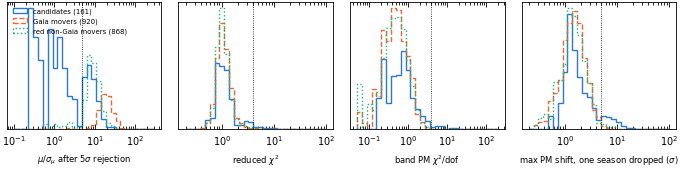

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 1.9))
for ax, k, lab, rng in zip(axes, ['snr_clip', 'rchi2', 'band_chi2', 'jackknife'],
                           [r'$\mu/\sigma_\mu$ after 5$\sigma$ rejection', r'reduced $\chi^2$', r'band PM $\chi^2$/dof',
                            'max PM shift, one season dropped ($\sigma$)'],
                           [(0.1, 300), (0.2, 100), (0.05, 200), (0.2, 100)]):
    bins = np.logspace(np.log10(rng[0]), np.log10(rng[1]), 30)
    for i, (X, lb, col, ls) in enumerate([(A, f'candidates ({len(A)})', ps.SERIES[0], '-'),
                                          (AG, f'Gaia movers ({len(AG)})', ps.SERIES[1], '--'),
                                          (AR, f'red non-Gaia movers ({len(AR)})', ps.SERIES[2], ':')]):
        x = X[:, NAMES.index(k)]; x = x[np.isfinite(x)]
        ax.hist(np.clip(x, *rng), bins, histtype='step', density=True, color=col, ls=ls, label=lb)
    ax.axvline(THRESH[k][1], color='k', lw=0.6, ls=':')
    ax.set_xscale('log'); ax.set_xlabel(lab, fontsize=6); ax.set_yticks([])
axes[0].legend(fontsize=5, loc='upper left')
fig.tight_layout()
fig.savefig(f'{PLOTS}/wdvet_astrometry_tests.pdf'); fig.savefig(f'{PLOTS}/wdvet_astrometry_tests.png')

Example epochs: the candidate with the most significant robust motion, and the one whose catalogue PM is most reduced by
epoch rejection (its 'motion' comes from a few epochs).

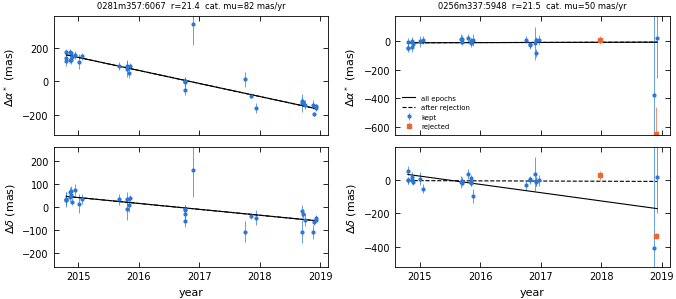

In [5]:
def epoch_plot(ax_pair, i):
    o = C[i]; k = int(o['brickid']) * 100000 + int(o['objid'])
    e = E[(E['brickid'].astype(np.int64) * 100000 + E['objid']) == k]
    f = wv.fit(e, o['ra'], o['dec']); fc, keep = wv.clipped_fit(e, o['ra'], o['dec'])
    yr = 2000 + (e['mjd'] - 51544.5) / wv.DAYS
    t = np.linspace(yr.min(), yr.max(), 2)
    pos = wv._pos(e)
    for ax, yy, pm, sig in [(ax_pair[0], pos[0], 'pmra', 'full_fit_dra_ivar_total'),
                            (ax_pair[1], pos[1], 'pmdec', 'full_fit_ddec_ivar_total')]:
        y = yy * 1000; s = 1 / np.sqrt(e[sig]) * 1000
        ax.errorbar(yr[keep], y[keep], s[keep], fmt='o', ms=2, lw=0.5, color=ps.SERIES[0], label='kept')
        if (~keep).any():
            ax.errorbar(yr[~keep], y[~keep], s[~keep], fmt='s', ms=2.5, lw=0.5, color=ps.SERIES[1], label='rejected')
        ref = np.average(yr, weights=1 / s**2)
        y0 = np.average(y - f[pm] * (yr - ref), weights=1 / s**2)
        ax.plot(t, y0 + f[pm] * (t - ref), color='k', lw=0.8, label='all epochs')
        if fc is not None:
            y0c = np.average((y - fc[pm] * (yr - ref))[keep], weights=1 / s[keep]**2)
            ax.plot(t, y0c + fc[pm] * (t - ref), color='k', lw=0.8, ls='--', label='after rejection')
        ax.set_ylim(np.percentile(y, 2) - 150, np.percentile(y, 98) + 150)
    ax_pair[0].set_ylabel(r'$\Delta\alpha^*$ (mas)'); ax_pair[1].set_ylabel(r'$\Delta\delta$ (mas)')
    ax_pair[0].set_title(f'{o["brickname"]}:{o["objid"]}  r={o["r"]:.1f}  cat. mu={o["mu"]:.0f} mas/yr', fontsize=6)

good_i = np.nanargmax(np.where(astro_ok, A[:, NAMES.index('snr_clip')], -1))
bad_i = np.nanargmin(A[:, NAMES.index('mu_ratio_clip')])
fig, axes = plt.subplots(2, 2, figsize=(ps.PAGE, 3.2), sharex=True)
epoch_plot(axes[:, 0], good_i); epoch_plot(axes[:, 1], bad_i)
axes[0, 1].legend(fontsize=5); axes[1, 0].set_xlabel('year'); axes[1, 1].set_xlabel('year')
fig.tight_layout()
fig.savefig(f'{PLOTS}/wdvet_epochs_examples.pdf'); fig.savefig(f'{PLOTS}/wdvet_epochs_examples.png')

## 2. Stacked parallax

`parallax_new` (5-parameter fit). Zero point and error scale from the clean Gaia stars in the same bricks (ours − Gaia),
and from the control sample (non-Gaia PSF, $r$ 21-23, $g - z < 1.5$, no significant PM: distant stars and QSOs, true
parallax ≈ 0). Predictions for the candidates that pass the astrometric tests: as white dwarfs (distance from the DA track
at their colour) and as subdwarfs (distance from the relation in section 3).

In [6]:
def wmean(x, ivar, scale=1.):
    m = np.isfinite(x) & (ivar > 0); w = ivar[m]
    return np.sum(x[m] * w) / w.sum(), scale / np.sqrt(w.sum()), m.sum()

def width(p):
    return 1.4826 * np.median(np.abs(p - np.median(p)))

g = (G['parallax_ivar'] > 0) & (G['parallax_new_ivar'] > 0)
dp = G['parallax_new'][g] - G['parallax'][g]; sdp = np.sqrt(1 / G['parallax_new_ivar'][g] + 1 / G['parallax_ivar'][g])
zp_g = wmean(dp, 1 / sdp**2, width(dp / sdp))
zp_c = wmean(K['parallax_new'], K['parallax_new_ivar'], width(K['parallax_new'] * np.sqrt(K['parallax_new_ivar'])))
w_c = width(K['parallax_new'] * np.sqrt(K['parallax_new_ivar']))
print(f'Gaia stars: ours - Gaia = {zp_g[0]:+.2f} +- {zp_g[1]:.2f} mas (N={zp_g[2]}), pull width {width(dp/sdp):.2f}')
print(f'control (true ~0): {zp_c[0]:+.2f} +- {zp_c[1]:.2f} mas (N={zp_c[2]}), pull width {w_c:.2f}, median sigma {np.median(1/np.sqrt(K["parallax_new_ivar"])):.1f} mas')
ZP = zp_c[0]   # faint-object zero point (the control sample matches the candidates in magnitude)

teff, gz_wd, Mr_wd = rpm.wd_tracks()['DA']; kk = teff >= 4500; oo = np.argsort(gz_wd[kk])
M_wd = np.interp(C['g_z'], gz_wd[kk][oo], Mr_wd[kk][oo])
plx_wd = 1000 / wv.distance_pc(C['r'], M_wd)
stack = {}
for lab, m in [('candidates, astrometry pass', astro_ok), ('candidates, astrometry fail', ~astro_ok)]:
    v, s, n = wmean(C['parallax_new'][m] - ZP, C['parallax_new_ivar'][m], w_c)
    pred = wmean(plx_wd[m], C['parallax_new_ivar'][m])[0]
    stack[lab] = (v, s, n, pred)
    print(f'{lab:28s} N={n:3d}: stacked parallax {v:+.2f} +- {s:.2f} mas (zero-point corrected, errors x{w_c:.2f}); '
          f'WD prediction {pred:.2f} mas')

Gaia stars: ours - Gaia = +0.09 +- 0.03 mas (N=12564), pull width 1.22
control (true ~0): -0.11 +- 0.16 mas (N=5642), pull width 1.09, median sigma 15.0 mas
candidates, astrometry pass  N= 98: stacked parallax +2.65 +- 1.12 mas (zero-point corrected, errors x1.09); WD prediction 2.67 mas
candidates, astrometry fail  N= 63: stacked parallax -4.46 +- 1.68 mas (zero-point corrected, errors x1.09); WD prediction 2.45 mas


## 3. The subdwarf hypothesis

$M_r(g-z)$ for high-velocity stars ($v_{\rm tan} > 200$ km/s) from clean Gaia stars with parallax/error > 5 in these bricks.
For each candidate: the distance and tangential velocity it would have as such a star. To be conservative (to make the
subdwarf velocity as small as possible), the relation is shifted 0.5 mag fainter, and objects bluer than the bluest halo
stars take the turnoff value (a bluer main-sequence star would be brighter, so farther and faster). The local escape speed
is ~550 km/s (e.g. Monari et al. 2018; Koppelman & Helmi 2021); tangential velocities above 600 km/s rule out a bound
main-sequence star.

In [7]:
good = (G['parallax'] * np.sqrt(G['parallax_ivar']) > 5) & (G['parallax'] > 0)
Mr_g = G['r'] + 5 * np.log10(np.where(good, G['parallax'], 1) / 100.)
vt_g = wv.vtan_kms(np.hypot(G['pmra'], G['pmdec']), 1000 / np.where(good, G['parallax'], np.nan))
halo = good & (vt_g > 200) & (G['g_z'] > 0.2) & (G['g_z'] < 2.2)
coef = np.polyfit(G['g_z'][halo], Mr_g[halo], 1)
resid = Mr_g[halo] - np.polyval(coef, G['g_z'][halo])
GZ_TO = np.percentile(G['g_z'][halo], 2)     # bluest halo stars ~ the turnoff
print(f'{halo.sum()} high-velocity Gaia stars: M_r = {coef[1]:.2f} + {coef[0]:.2f} (g-z), scatter {width(resid):.2f} mag; '
      f'turnoff g-z = {GZ_TO:.2f}')
M_sd = np.polyval(coef, np.maximum(C['g_z'], GZ_TO)) + 0.5
sig_mu = np.sqrt(C['pmra_no_plx']**2 / C['pmra_no_plx_ivar'] + C['pmdec_no_plx']**2 / C['pmdec_no_plx_ivar']) / C['mu']
mu_lo = np.maximum(C['mu'] - 2 * sig_mu, 0)
v_sd = wv.vtan_kms(mu_lo, wv.distance_pc(C['r'], M_sd))   # conservative: mu - 2 sigma, relation +0.5 mag
v_wd = wv.vtan_kms(C['mu'], wv.distance_pc(C['r'], M_wd))
blue = C['g_z'] < GZ_TO
print(f'astrometry pass: {astro_ok.sum()}; of these bluer than the halo turnoff: {np.sum(astro_ok & blue)}; '
      f'v_sd > 600 km/s: {np.sum(astro_ok & (v_sd > 600))}; 300-600: {np.sum(astro_ok & (v_sd > 300) & (v_sd <= 600))}; '
      f'< 300: {np.sum(astro_ok & (v_sd <= 300))}  (with mu - 2 sigma)')
print('v_wd (km/s) of astrometry-pass candidates, 10/50/90%:', np.percentile(v_wd[astro_ok], [10, 50, 90]).round(0))

149 high-velocity Gaia stars: M_r = 3.50 + 2.55 (g-z), scatter 0.52 mag; turnoff g-z = 0.28
astrometry pass: 98; of these bluer than the halo turnoff: 36; v_sd > 600 km/s: 98; 300-600: 0; < 300: 0  (with mu - 2 sigma)
v_wd (km/s) of astrometry-pass candidates, 10/50/90%: [ 43.  80. 153.]


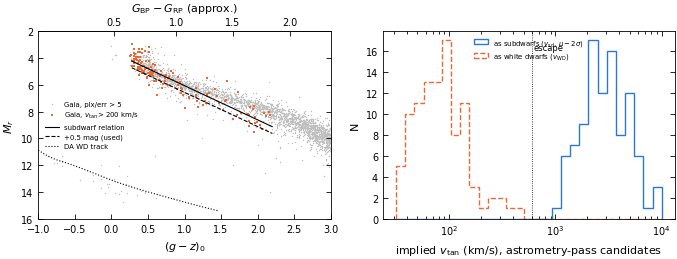

In [8]:
REL = np.load(f'{OUT}/bprp_relation.npz')   # Gaia BP - RP vs g - z and g - r, from rpm-diagram.ipynb
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 2.8))
ax = axes[0]
ax.scatter(G['g_z'][good & ~halo], Mr_g[good & ~halo], s=1, color='0.75', lw=0, label='Gaia, plx/err > 5')
ax.scatter(G['g_z'][halo], Mr_g[halo], s=3, color=ps.SERIES[1], marker=ps.MARKERS[1], lw=0, label=r'Gaia, $v_{\rm tan} > 200$ km/s')
x = np.linspace(GZ_TO, 2.2, 10)
ax.plot(x, np.polyval(coef, x), color='k', lw=0.8, label='subdwarf relation')
ax.plot(x, np.polyval(coef, x) + 0.5, color='k', lw=0.8, ls='--', label='+0.5 mag (used)')
ax.plot(gz_wd[kk], Mr_wd[kk], color='k', lw=0.8, ls=':', label='DA WD track')
ax.set_xlim(-1, 3); ax.set_ylim(16, 2); ax.set_xlabel(r'$(g-z)_0$'); ax.set_ylabel(r'$M_r$'); ax.legend(fontsize=5)
rpm.add_bprp_axis(ax, REL['g_z'])
ax = axes[1]
bins = np.logspace(1.5, 4, 30)
ax.hist(np.clip(v_sd[astro_ok], 32, 9999), bins, histtype='step', color=ps.SERIES[0], label=r'as subdwarfs ($v_{\rm sd}$, $\mu - 2\sigma$)')
ax.hist(np.clip(v_wd[astro_ok], 32, 9999), bins, histtype='step', ls='--', color=ps.SERIES[1], label=r'as white dwarfs ($v_{\rm WD}$)')
ax.axvline(600, color='k', lw=0.6, ls=':'); ax.text(620, ax.get_ylim()[1] * 0.9, 'escape', fontsize=6)
ax.set_xscale('log'); ax.set_xlabel(r'implied $v_{\rm tan}$ (km/s), astrometry-pass candidates'); ax.set_ylabel('N'); ax.legend(fontsize=5)
fig.tight_layout()
fig.savefig(f'{PLOTS}/wdvet_subdwarf_test.pdf'); fig.savefig(f'{PLOTS}/wdvet_subdwarf_test.png')

## 4. Colours and images

W1 detections (S/N > 3): 30 of 161 -- mostly too faint for WISE, as expected at r ~ 22
fracflux_r > 0.1 (light from neighbours): 18


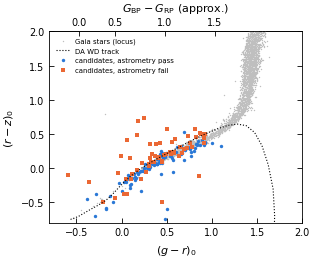

In [9]:
gr = lambda T: T['g'] - T['r']; rz = lambda T: T['r'] - T['z']
te, gzt, _ = rpm.wd_tracks()['DA']
a = np.loadtxt(rpm.WD_TABLE, skiprows=2, max_rows=61)
fig, ax = plt.subplots(figsize=(ps.COLUMN, 2.8))
gs = good & (G['r'] < 20)
ax.scatter(gr(G)[gs], rz(G)[gs], s=1, color='0.75', lw=0, label='Gaia stars (locus)')
ax.plot(a[:, 25] - a[:, 26], a[:, 26] - a[:, 28], color='k', lw=0.8, ls=':', label='DA WD track')
for i, (m, lab) in enumerate([(astro_ok, 'astrometry pass'), (~astro_ok, 'astrometry fail')]):
    ax.scatter(gr(C)[m], rz(C)[m], s=6, marker=ps.MARKERS[i], color=ps.SERIES[i], lw=0, label=f'candidates, {lab}')
ax.set_xlim(-0.8, 2); ax.set_ylim(-0.8, 2); ax.set_xlabel(r'$(g-r)_0$'); ax.set_ylabel(r'$(r-z)_0$'); ax.legend(fontsize=5)
rpm.add_bprp_axis(ax, np.load(f'{OUT}/bprp_relation.npz')['g_r'], ticks=[0, 0.5, 1, 1.5])   # g - r stops tracking BP - RP redder
fig.tight_layout()
fig.savefig(f'{PLOTS}/wdvet_colours.pdf'); fig.savefig(f'{PLOTS}/wdvet_colours.png')
w1 = C['flux_w1'] * np.sqrt(C['flux_ivar_w1'])
print(f'W1 detections (S/N > 3): {np.sum(w1 > 3)} of {len(C)} -- mostly too faint for WISE, as expected at r ~ 22')
print(f'fracflux_r > 0.1 (light from neighbours): {np.sum(C["fracflux_r"] > 0.1)}')

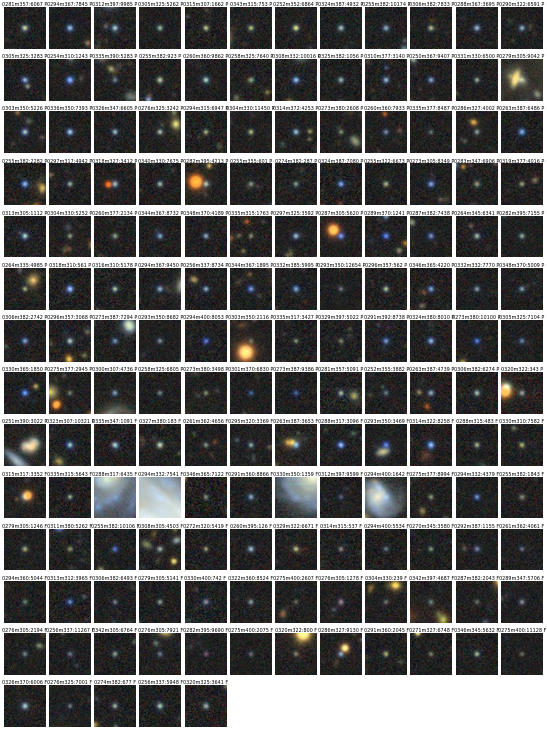

In [10]:
CUT = f'{OUT}/cutouts'; os.makedirs(CUT, exist_ok=True)
def cutout(o, layer='ls-dr10', size=48):
    fn = f'{CUT}/{o["brickname"]}_{o["objid"]}_{layer}.jpg'
    if not os.path.exists(fn):
        url = (f'https://www.legacysurvey.org/viewer/cutout.jpg?ra={o["ra"]:.6f}&dec={o["dec"]:.6f}'
               f'&layer={layer}&pixscale=0.262&size={size}')
        try:
            urllib.request.urlretrieve(url, fn)
        except Exception as err:
            print('failed', fn, err); return None
    return plt.imread(fn)

order = np.lexsort((-A[:, NAMES.index('snr_clip')], ~astro_ok))
ncol = 12; nrow = int(np.ceil(len(C) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(ps.PAGE, ps.PAGE / ncol * nrow * 1.15))
for ax in axes.flat: ax.axis('off')
for ax, i in zip(axes.flat, order):
    im = cutout(C[i])
    if im is not None: ax.imshow(im, origin='upper')
    ax.set_title(f'{str(C["brickname"][i]).strip()}:{C["objid"][i]} {"P" if astro_ok[i] else "F"}', fontsize=3.5, pad=1)
fig.subplots_adjust(wspace=0.05, hspace=0.25)
fig.savefig(f'{PLOTS}/wdvet_cutouts.png', dpi=300)

## 5. Grades

- **A, strong white-dwarf candidate:** passes the astrometric tests, clean image, and either bluer than the halo turnoff or
  would need $v_{\rm tan} > 600$ km/s as a subdwarf even with $\mu - 2\sigma_\mu$.
- **B, white-dwarf candidate with a caveat:** passes the astrometric tests, but the image shows a blend / artefact, or the
  subdwarf velocity (with $\mu - 2\sigma_\mu$) is below 600 km/s.
- **X, motion not robust:** fails the astrometric tests (likely spurious PM).
Image flags come from looking at `plots/wdvet_cutouts.png` (2026-10-27) and are keyed by brick:objid.

In [11]:
IMAGE_FLAG = {('0279m305', 9042): 'blended with a galaxy', ('0293m350', 3469): 'blended with a galaxy',
              ('0294m332', 7541): 'inside a bright galaxy', ('0282m395', 4213): 'next to a bright star',
              ('0287m305', 5620): 'touching a brighter star', ('0314m322', 8758): 'touching a brighter star',
              ('0318m327', 3412): 'touching a brighter star',
              # inspected after the error-model v3 rerun (new candidates; image + residual cutouts)
              ('0251m390', 3022): 'blended with a galaxy', ('0320m322', 343): 'next to a bright star'}
img = np.array([IMAGE_FLAG.get((str(b).strip(), int(o)), '') for b, o in zip(C['brickname'], C['objid'])])
wd_like = blue | (v_sd > 600)
grade = np.where(~astro_ok, 'X', np.where(wd_like & (img == ''), 'A', 'B'))
for gname in 'ABX':
    print(gname, np.sum(grade == gname))
for gname in 'ABX':
    m = grade == gname
    if m.sum() == 0: continue
    v, s, n = wmean(C['parallax_new'][m] - ZP, C['parallax_new_ivar'][m], w_c)
    pred = wmean(plx_wd[m], C['parallax_new_ivar'][m])[0]
    print(f'grade {gname}: stacked parallax {v:+.2f} +- {s:.2f} mas (N={n}); WD prediction {pred:.2f}')

A 92
B 6
X 63
grade A: stacked parallax +3.19 +- 1.17 mas (N=92); WD prediction 2.65
grade B: stacked parallax -3.97 +- 4.07 mas (N=6); WD prediction 2.84
grade X: stacked parallax -4.46 +- 1.68 mas (N=63); WD prediction 2.45


Independent check of the astrometric tests: PM directions. Real movers share the solar reflex motion (in this field
most HPM stars move towards position angles 45-225 deg: 91% of the Gaia candidates in the white-dwarf region, 50% for random
directions). If the tests work, the candidates that pass should look like real movers and those that fail closer to random.

In [12]:
pa = np.degrees(np.arctan2(C['pmra_no_plx'], C['pmdec_no_plx'])) % 360
half = (pa > 45) & (pa < 225)
pg = np.degrees(np.arctan2(RH['pmra_no_plx'], RH['pmdec_no_plx'])) % 360
print(f'red non-Gaia movers: {100*np.mean((pg > 45) & (pg < 225)):.0f}% in the reflex half')
for lab, m in [('pass (A+B)', astro_ok), ('fail (X)', ~astro_ok)]:
    f = half[m].mean()
    print(f'{lab:12s} N={m.sum():3d}: {100*f:.0f}% in the reflex half -> real fraction ~{(f - 0.5) / (0.91 - 0.5):.2f} '
          f'(0.91 real, 0.50 random)')

red non-Gaia movers: 98% in the reflex half
pass (A+B)   N= 98: 90% in the reflex half -> real fraction ~0.97 (0.91 real, 0.50 random)
fail (X)     N= 63: 65% in the reflex half -> real fraction ~0.37 (0.91 real, 0.50 random)


In [13]:
out = {k: C[k] for k in ('brickname', 'objid', 'ra', 'dec', 'g', 'r', 'z', 'g_z', 'mu', 'mu_err', 'H_r',
                         'pmra_no_plx', 'pmdec_no_plx', 'parallax_new', 'parallax_new_ivar', 'pm_n_epochs')}
for k in NAMES[2:]:
    out[k] = A[:, NAMES.index(k)]
out.update(M_wd=M_wd, v_wd=v_wd, M_sd=M_sd, v_sd=v_sd, plx_wd_pred=plx_wd,
           astro_ok=astro_ok, grade=grade.astype('U1'),
           image_flag=img.astype('U40'))
fitsio.write(f'{OUT}/wd_candidates_vetted.fits', out, names=list(out), clobber=True)
import csv
with open(f'{OUT}/wd_candidates_vetted.csv', 'w', newline='') as fh:
    wr = csv.writer(fh); keys = list(out); wr.writerow(['index'] + keys)
    for i in np.argsort(grade):
        wr.writerow([i] + [f'{out[k][i]:.6f}' if isinstance(out[k][i], (float, np.floating)) else out[k][i] for k in keys])
print('wrote', f'{OUT}/wd_candidates_vetted.fits/.csv')

wrote output/wd_candidates_vetted.fits/.csv
